In [17]:
import numpy as np
import matplotlib.pyplot as plt

import pywt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.fft import dct, idct
import jlinops

import sys
import os

from wavelets import WaveletTransformOperator2D

import jlinops

import matplotlib.gridspec as gridspec

from msolver import IASGKS, MMGKS, VanillaGKS
from fsolver import MMFGK

# Setup toy problem

In [18]:
image = jlinops.cameraman()
img_shape = image.shape
x_true = image.flatten()

noise_sigma = 0.05
A = jlinops.Gaussian2DBlurOperator(img_shape, blur_sigma=2.0, mode="wrap")
#A = WaveletTransformOperator2D(img_shape, wavelet="haar", level=3)
b_true = A @ x_true
b = b_true + noise_sigma*np.random.normal(size=A.shape[0])
naive_recon = A.T @ b
noise_var = noise_sigma**2

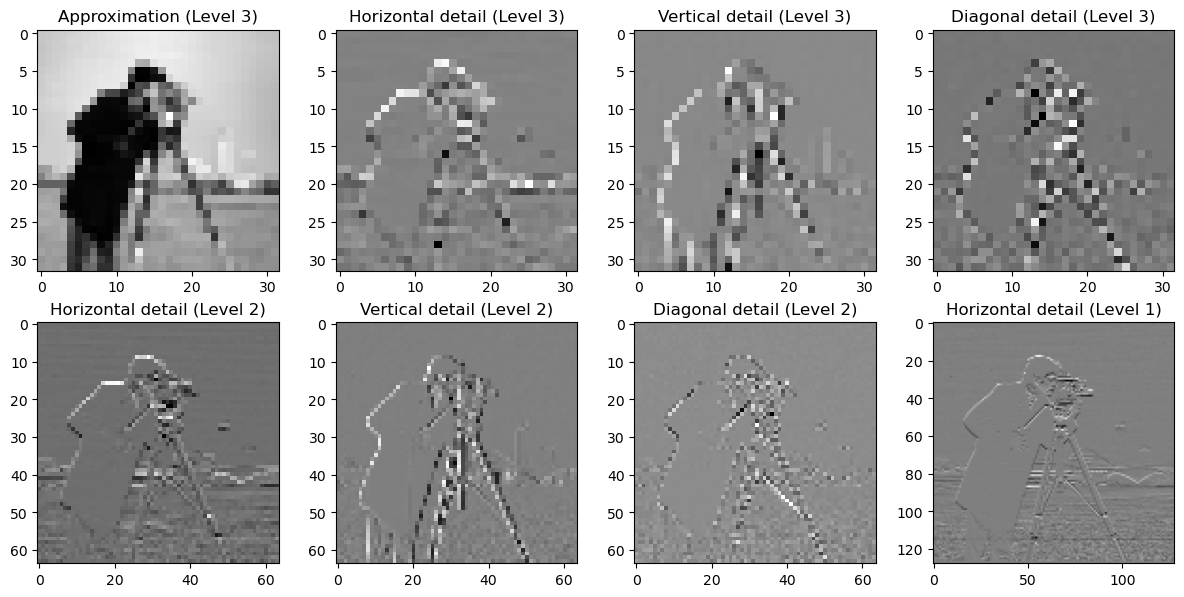

In [19]:
# Create a sample 2D image (e.g., 256x256 random matrix)

# Perform 2D wavelet decomposition using Haar wavelet, with 3 levels
coeffs = pywt.wavedec2(image, 'haar', level=3)

# coeffs is a list containing the approximation coefficients and detail coefficients
# The first element of coeffs is the approximation coefficient at level 3
# The subsequent elements are tuples of detail coefficients (horizontal, vertical, diagonal) for each level

# Extract the approximation coefficients at the final level (level 3)
cA3 = coeffs[0]

# Extract the detail coefficients (cH, cV, cD) for each level
(cH3, cV3, cD3), (cH2, cV2, cD2), (cH1, cV1, cD1) = coeffs[1:]

# Plotting the approximation and detail coefficients for visualization
fig, ax = plt.subplots(2, 4, figsize=(12, 6))

# Level 3 coefficients
ax[0, 0].imshow(cA3, cmap='gray')
ax[0, 0].set_title('Approximation (Level 3)')

ax[0, 1].imshow(cH3, cmap='gray')
ax[0, 1].set_title('Horizontal detail (Level 3)')

ax[0, 2].imshow(cV3, cmap='gray')
ax[0, 2].set_title('Vertical detail (Level 3)')

ax[0, 3].imshow(cD3, cmap='gray')
ax[0, 3].set_title('Diagonal detail (Level 3)')

# Level 2 coefficients
ax[1, 0].imshow(cH2, cmap='gray')
ax[1, 0].set_title('Horizontal detail (Level 2)')

ax[1, 1].imshow(cV2, cmap='gray')
ax[1, 1].set_title('Vertical detail (Level 2)')

ax[1, 2].imshow(cD2, cmap='gray')
ax[1, 2].set_title('Diagonal detail (Level 2)')

# Level 1 coefficients
ax[1, 3].imshow(cH1, cmap='gray')
ax[1, 3].set_title('Horizontal detail (Level 1)')

# Adjust layout and show the plot
plt.tight_layout()
plt.show()


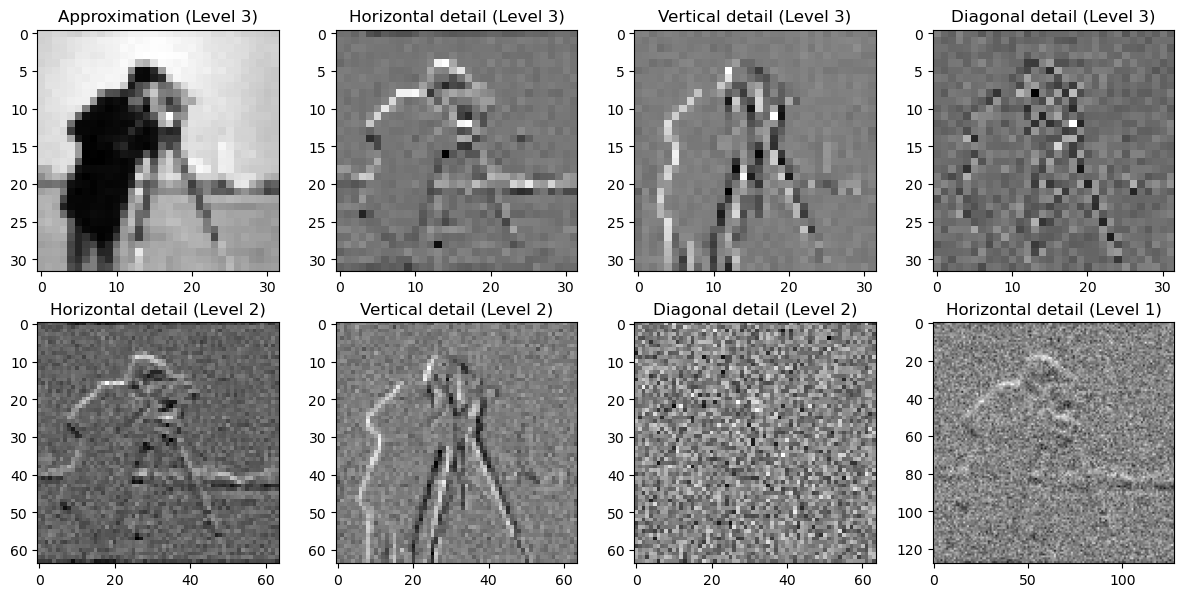

In [20]:
# Create a sample 2D image (e.g., 256x256 random matrix)

# Perform 2D wavelet decomposition using Haar wavelet, with 3 levels
coeffs = pywt.wavedec2(b.reshape(img_shape), 'haar', level=3)

# coeffs is a list containing the approximation coefficients and detail coefficients
# The first element of coeffs is the approximation coefficient at level 3
# The subsequent elements are tuples of detail coefficients (horizontal, vertical, diagonal) for each level

# Extract the approximation coefficients at the final level (level 3)
cA3 = coeffs[0]

# Extract the detail coefficients (cH, cV, cD) for each level
(cH3, cV3, cD3), (cH2, cV2, cD2), (cH1, cV1, cD1) = coeffs[1:]

# Plotting the approximation and detail coefficients for visualization
fig, ax = plt.subplots(2, 4, figsize=(12, 6))

# Level 3 coefficients
ax[0, 0].imshow(cA3, cmap='gray')
ax[0, 0].set_title('Approximation (Level 3)')

ax[0, 1].imshow(cH3, cmap='gray')
ax[0, 1].set_title('Horizontal detail (Level 3)')

ax[0, 2].imshow(cV3, cmap='gray')
ax[0, 2].set_title('Vertical detail (Level 3)')

ax[0, 3].imshow(cD3, cmap='gray')
ax[0, 3].set_title('Diagonal detail (Level 3)')

# Level 2 coefficients
ax[1, 0].imshow(cH2, cmap='gray')
ax[1, 0].set_title('Horizontal detail (Level 2)')

ax[1, 1].imshow(cV2, cmap='gray')
ax[1, 1].set_title('Vertical detail (Level 2)')

ax[1, 2].imshow(cD2, cmap='gray')
ax[1, 2].set_title('Diagonal detail (Level 2)')

# Level 1 coefficients
ax[1, 3].imshow(cH1, cmap='gray')
ax[1, 3].set_title('Horizontal detail (Level 1)')

# Adjust layout and show the plot
plt.tight_layout()
plt.show()


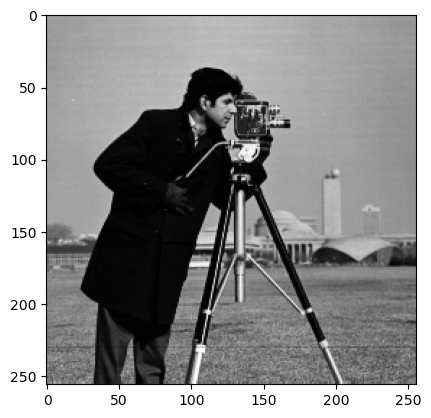

In [21]:
plt.imshow(image, cmap="gray")
plt.show()

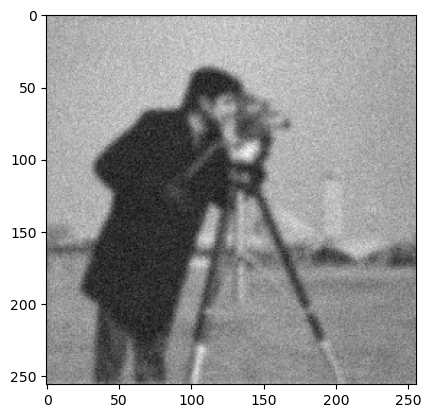

In [22]:
plt.imshow(b.reshape(img_shape), cmap="gray")
plt.show()

# Set up prior

In [8]:
# This can be figured out later
# mask = np.zeros(Lpre.shape[0])
# mask[ Lpre.detail_indices ] = 1
# P = jlinops.Subsampling1DOperator(mask)
#L = P @ Lpre

L = WaveletTransformOperator2D(img_shape, wavelet="haar", level=3)
K = None
Lpinv_factory = lambda wr: L.T @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

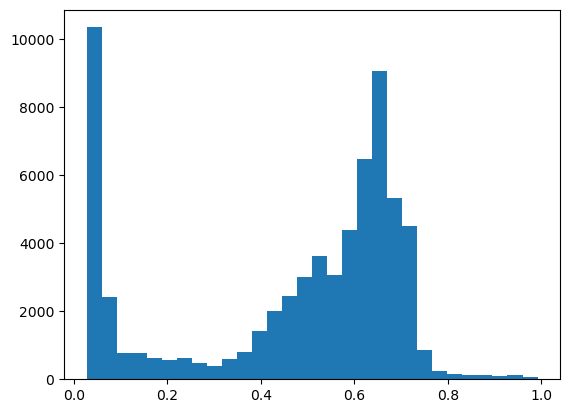

In [48]:
plt.hist(ground_truth, bins=30)
plt.show()

In [23]:
# Set method
method = "dp"

# Weight params
q = 1.0
epsilon = 1e-4
weight_params = {
    "q": q,
    "epsilon": epsilon,
}

# Build solver
mmgks_solver = MMGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
mmfk_solver = MMFGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

xker = None
ground_truth = x_true.copy()

In [24]:
vdata = gks_solver.solve(n_iter=50, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params={},
                                    regparam_kwargs={"eta":1.01},  xker=xker)

pdata = mmgks_solver.solve_with_priorconditioning(n_iter=50, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, weight_params=weight_params, 
                                                 regparam_kwargs={"eta":1.01})


data = mmgks_solver.solve(n_iter=50, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)


mmfkdata = mmfk_solver.solve(n_iter=50, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )


rmmfkdata = mmfk_solver.solve(n_iter=50, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=weight_params, refresh_basis=True,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

10.724801042551581
11.245175999333734
11.557919876970098
11.73685094228146
11.836800091993537
11.89395774962219
11.926101792374034
11.944143770628425
11.95404504528972
11.95939002397508
11.96225996006392
11.963842349838187
11.964663217463038
11.965116762151567
11.96535314704975
11.96547887841011
11.965545107361294
11.965579991896208
11.965598827575672
11.965608666548215
11.965613940417626
11.96561659645662
11.965617966636325
11.965618705320109
11.96561907691468
11.965619278317664
11.965619382949319
11.965619437894732
11.965619465358422
11.965619478818757
11.965619486129038
11.965619489888958
11.965619491818936
11.965619492838742
11.965619493340597
11.965619493610289
11.965619493744146
11.965619493813826
11.965619493850838
11.965619493869532
11.965619493879323
11.965619493884038
11.965619493886368
11.965619493887734
11.965619493888372
11.965619493888825
11.965619493888891
11.965619493889015
11.965619493889065
11.965619493889031
Augmented basis with initial guess!


1e-07


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/tests/2d_blur_wavelets/../../msolver.py:784: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
0.22430565435213
4.216257905547323
5.448870739645071
6.450570217622304
7.181287663034488
7.698540437182639
8.121110351516426
8.461842064052199
8.770768351854167
9.043878407833803
9.244857630913108
9.402135644511528
9.539676739112357
9.68126404363557
9.804248873781729
9.914898048709457
10.012629954294356
10.091801989789804
10.142966876199266
10.180920370150687
10.20725557226327
10.219363934042349
10.232020438002182
10.243241773445336
10.250867132393475
10.253598826548279
10.2553492079445
10.260288149394881
10.263141374602746
10.264774571084635
10.265241114309239
10.26426150321193
Augmented basis with initial guess!


18.151448692794197
12.119899199362042
11.752931060704865
10.254092391649197
10.273855315658444
9.962173063611795
9.746805441710384
9.576180525462163
9.352646096067376
9.254270140334635
9.224333954596698
9.100353565989765
8.979566167519884
8.897148398928664
8.893989435080732
8.786672610341446
8.761473496517645
8.729896725658213
8.679826949128104
8.634720574076812
8.611379738239597
8.600675648604916
8.568452904287224
8.541025840536587
8.52113022161728
8.51228945950823
8.509484310676402
8.516617519083718
8.499361178417404
8.504350816023546
8.506702645856118
8.491552858900263
8.483078907248114
8.48233563818573
8.482689575076513
8.48533901438891
8.480270534033535
8.471801189576718
8.457684946566921
8.414171535796193
8.39345594205135
8.377157949194457
8.331723562843857
8.315913883415176
8.319406865634663
8.336932787562947
8.363724592859265
8.395403376563973
8.431263440644845
8.486277087653608
Starting iteration 0
1e-14
Starting iteration 1
1e-14
Starting iteration 2
1e-14
Starting iteration 

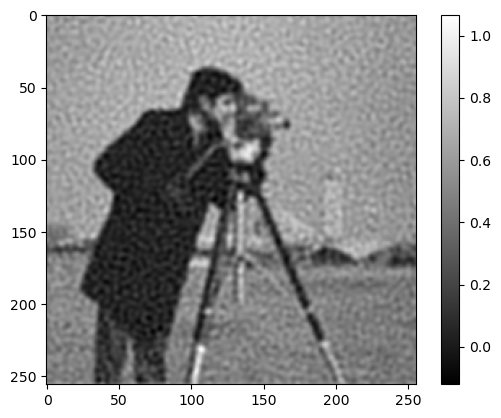

In [26]:
plt.imshow(vdata["x"].reshape(img_shape), cmap="gray")
plt.colorbar()
plt.show()

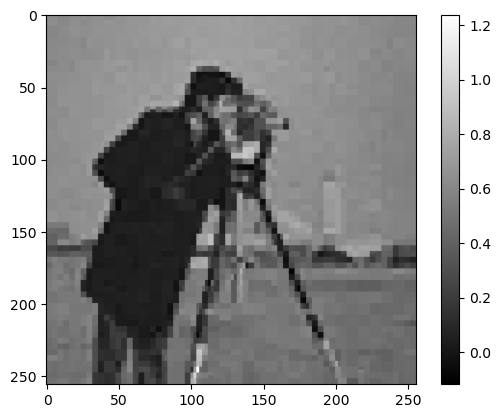

In [27]:
plt.imshow(pdata["x"].reshape(img_shape), cmap="gray")
plt.colorbar()
plt.show()

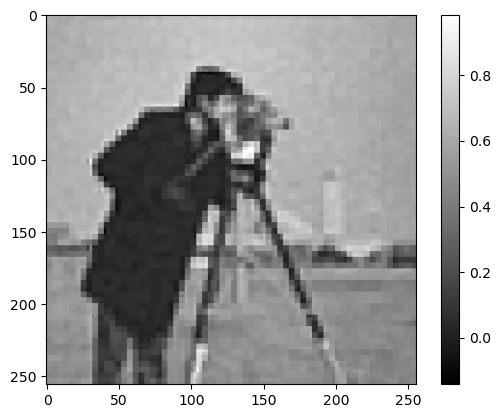

In [28]:
plt.imshow(data["x"].reshape(img_shape), cmap="gray")
plt.colorbar()
plt.show()

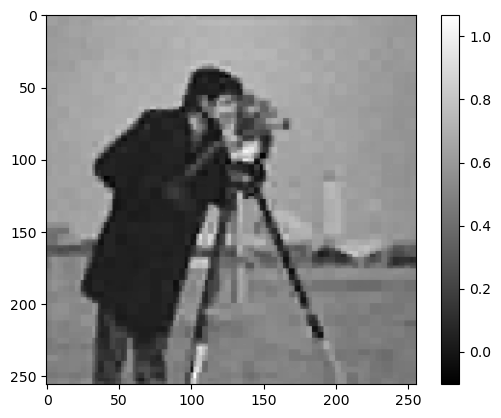

In [29]:
plt.imshow(mmfkdata["x"].reshape(img_shape), cmap="gray")
plt.colorbar()
plt.show()

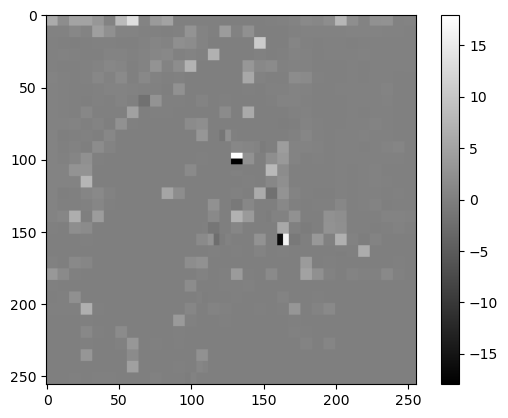

In [30]:
plt.imshow(rmmfkdata["x"].reshape(img_shape), cmap="gray")
plt.colorbar()
plt.show()

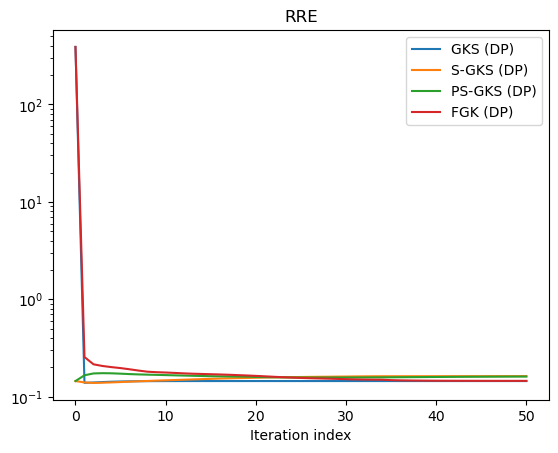

In [39]:
plt.semilogy(vdata["rre_history"], label="GKS (DP)")
plt.semilogy(data["rre_history"], label="S-GKS (DP)")
# plt.semilogy(data_opt["rre_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(pdata["rre_history"], label="PS-GKS (DP)")
plt.semilogy(mmfkdata["rre_history"], label="FGK (DP)")
# plt.semilogy(pdata_opt["rre_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

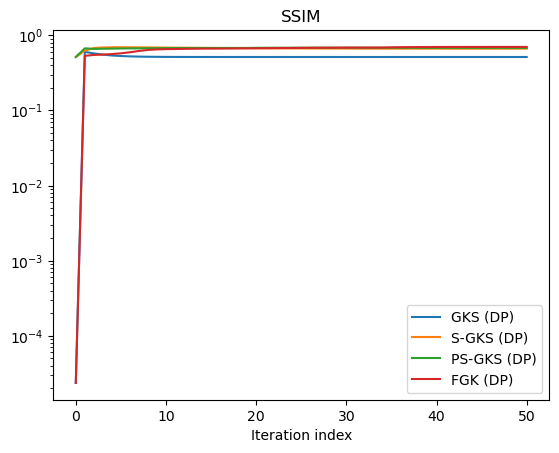

In [37]:
plt.semilogy(vdata["ssim_history"], label="GKS (DP)")
plt.semilogy(data["ssim_history"], label="S-GKS (DP)")
# plt.semilogy(data_opt["rre_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(pdata["ssim_history"], label="PS-GKS (DP)")
plt.semilogy(mmfkdata["ssim_history"], label="FGK (DP)")
# plt.semilogy(pdata_opt["rre_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.title("SSIM")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

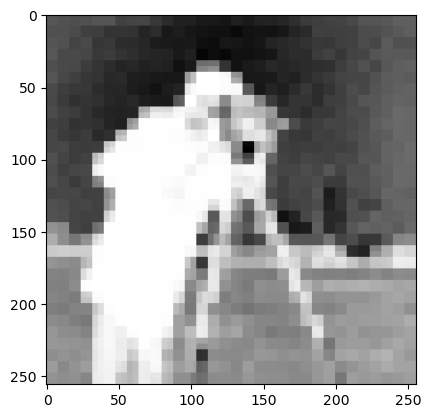

In [16]:
plt.imshow( (pdata["Lopinv"] @ pdata["V"][:,0]).reshape(img_shape) , cmap="gray")
plt.show()

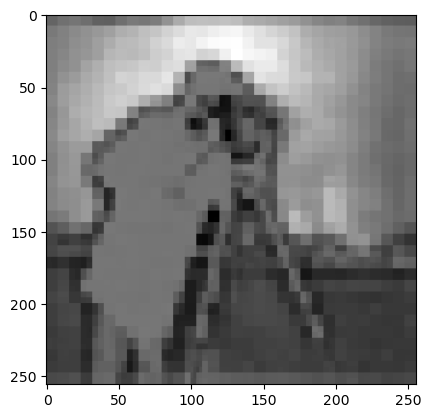

In [41]:
plt.imshow( (pdata["Lopinv"] @ pdata["V"][:,1]).reshape(img_shape) , cmap="gray")
plt.show()

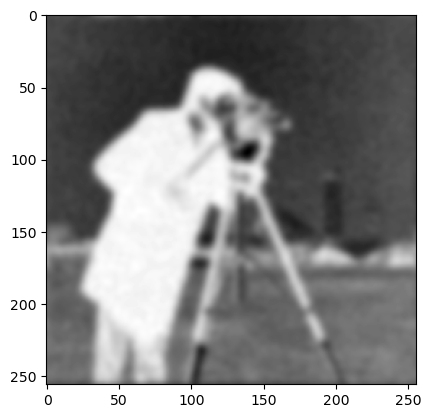

In [42]:
plt.imshow( (data["V"][:,0]).reshape(img_shape) , cmap="gray")
plt.show()

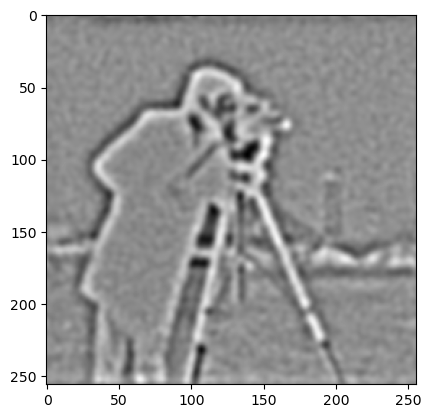

In [43]:
plt.imshow( (data["V"][:,1]).reshape(img_shape) , cmap="gray")
plt.show()

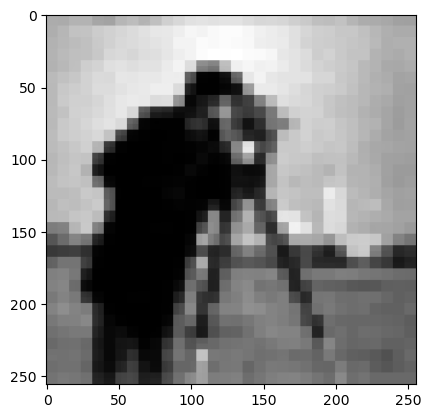

In [46]:
plt.imshow( (mmfkdata["Z"][:,0]).reshape(img_shape) , cmap="gray")
plt.show()